In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [9]:
import os
print(os.getcwd())

c:\Users\Ganesh Agrawal\Dynamic-Supply-Chain-Predictor\notebooks


In [10]:
import pandas as pd

df = pd.read_csv("../data/sales_data.csv")

print(df.shape)

(76000, 16)


In [16]:
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [12]:
df.tail()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
75995,2024-01-30,S005,P0016,Toys,North,233,63,0,29.80,5,Snowy,0,32.23,Winter,0,64
75996,2024-01-30,S005,P0017,Toys,North,137,115,141,42.92,5,Snowy,0,40.73,Winter,0,137
75997,2024-01-30,S005,P0018,Clothing,North,197,44,0,17.81,10,Snowy,0,19.41,Winter,0,68
75998,2024-01-30,S005,P0019,Furniture,North,125,58,0,151.72,0,Snowy,0,143.71,Winter,0,84
75999,2024-01-30,S005,P0020,Toys,North,126,63,59,25.78,10,Snowy,0,29.32,Winter,0,73


In [13]:
df.columns

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount',
       'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality',
       'Epidemic', 'Demand'],
      dtype='str')

In [14]:
df.shape

(76000, 16)

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Date                76000 non-null  str    
 1   Store ID            76000 non-null  str    
 2   Product ID          76000 non-null  str    
 3   Category            76000 non-null  str    
 4   Region              76000 non-null  str    
 5   Inventory Level     76000 non-null  int64  
 6   Units Sold          76000 non-null  int64  
 7   Units Ordered       76000 non-null  int64  
 8   Price               76000 non-null  float64
 9   Discount            76000 non-null  int64  
 10  Weather Condition   76000 non-null  str    
 11  Promotion           76000 non-null  int64  
 12  Competitor Pricing  76000 non-null  float64
 13  Seasonality         76000 non-null  str    
 14  Epidemic            76000 non-null  int64  
 15  Demand              76000 non-null  int64  
dtypes: float64(2), 

In [17]:
df['Date'] = pd.to_datetime(df['Date'])

In [18]:
df['Date'].dtype

dtype('<M8[us]')

In [19]:
df.isnull().sum()

Date                  0
Store ID              0
Product ID            0
Category              0
Region                0
Inventory Level       0
Units Sold            0
Units Ordered         0
Price                 0
Discount              0
Weather Condition     0
Promotion             0
Competitor Pricing    0
Seasonality           0
Epidemic              0
Demand                0
dtype: int64

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
daily_demand = df.groupby('Date')['Demand'].sum().reset_index()

daily_demand.head()

,Date,Demand
0,2022-01-01,10060
1,2022-01-02,10814
2,2022-01-03,11317
3,2022-01-04,11469
4,2022-01-05,11724


In [22]:
daily_demand.shape

(760, 2)

In [23]:
daily_demand.head()

,Date,Demand
0,2022-01-01,10060
1,2022-01-02,10814
2,2022-01-03,11317
3,2022-01-04,11469
4,2022-01-05,11724


In [24]:
daily_demand.tail()

,Date,Demand
755,2024-01-26,11182
756,2024-01-27,11540
757,2024-01-28,11440
758,2024-01-29,10268
759,2024-01-30,9657


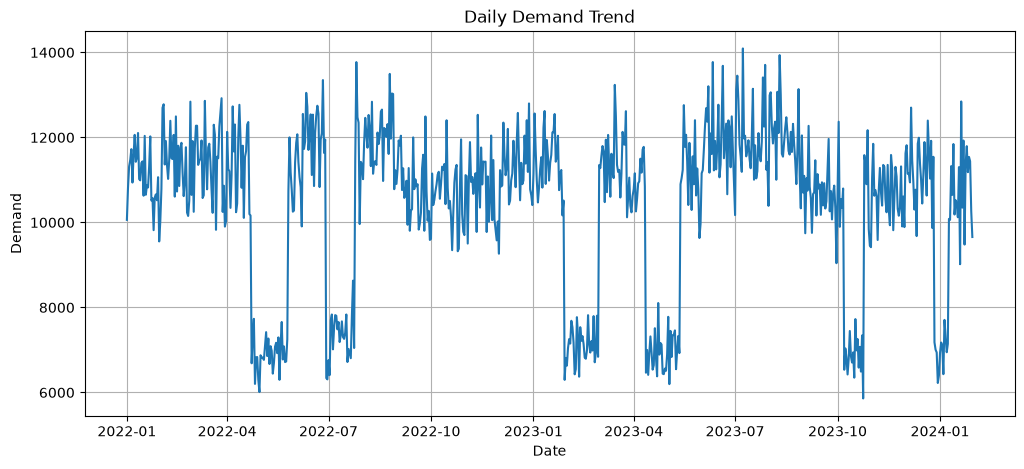

In [25]:
plt.figure(figsize=(12,5))

plt.plot(daily_demand['Date'], daily_demand['Demand'])

plt.title('Daily Demand Trend')
plt.xlabel('Date')
plt.ylabel('Demand')
plt.grid(True)

plt.show()

In [26]:
daily_demand['Year'] = daily_demand['Date'].dt.year
daily_demand['Month'] = daily_demand['Date'].dt.month
daily_demand['Day'] = daily_demand['Date'].dt.day
daily_demand['DayOfWeek'] = daily_demand['Date'].dt.dayofweek

daily_demand.head()

,Date,Demand,Year,Month,Day,DayOfWeek
0,2022-01-01,10060,2022,1,1,5
1,2022-01-02,10814,2022,1,2,6
2,2022-01-03,11317,2022,1,3,0
3,2022-01-04,11469,2022,1,4,1
4,2022-01-05,11724,2022,1,5,2


In [27]:
daily_demand['Lag_1'] = daily_demand['Demand'].shift(1)

daily_demand.head()

,Date,Demand,Year,Month,Day,DayOfWeek,Lag_1
0,2022-01-01,10060,2022,1,1,5,NaN
1,2022-01-02,10814,2022,1,2,6,10060.0
2,2022-01-03,11317,2022,1,3,0,10814.0
3,2022-01-04,11469,2022,1,4,1,11317.0
4,2022-01-05,11724,2022,1,5,2,11469.0


In [28]:
daily_demand['Lag_7'] = daily_demand['Demand'].shift(7)

daily_demand.head(10)

,Date,Demand,Year,Month,Day,DayOfWeek,Lag_1,Lag_7
0,2022-01-01,10060,2022,1,1,5,NaN,NaN
1,2022-01-02,10814,2022,1,2,6,10060.0,NaN
2,2022-01-03,11317,2022,1,3,0,10814.0,NaN
3,2022-01-04,11469,2022,1,4,1,11317.0,NaN
4,2022-01-05,11724,2022,1,5,2,11469.0,NaN
5,2022-01-06,10938,2022,1,6,3,11724.0,NaN
6,2022-01-07,11584,2022,1,7,4,10938.0,NaN
7,2022-01-08,12060,2022,1,8,5,11584.0,10060.0
8,2022-01-09,11427,2022,1,9,6,12060.0,10814.0
9,2022-01-10,11523,2022,1,10,0,11427.0,11317.0


In [29]:
daily_demand['Rolling_7'] = daily_demand['Demand'].shift(1).rolling(7).mean()

daily_demand.head(10)

,Date,Demand,Year,Month,Day,DayOfWeek,Lag_1,Lag_7,Rolling_7
0,2022-01-01,10060,2022,1,1,5,NaN,NaN,NaN
1,2022-01-02,10814,2022,1,2,6,10060.0,NaN,NaN
2,2022-01-03,11317,2022,1,3,0,10814.0,NaN,NaN
3,2022-01-04,11469,2022,1,4,1,11317.0,NaN,NaN
4,2022-01-05,11724,2022,1,5,2,11469.0,NaN,NaN
5,2022-01-06,10938,2022,1,6,3,11724.0,NaN,NaN
6,2022-01-07,11584,2022,1,7,4,10938.0,NaN,NaN
7,2022-01-08,12060,2022,1,8,5,11584.0,10060.0,11129.428571
8,2022-01-09,11427,2022,1,9,6,12060.0,10814.0,11415.142857
9,2022-01-10,11523,2022,1,10,0,11427.0,11317.0,11502.714286


In [30]:
daily_demand = daily_demand.dropna().reset_index(drop=True)

daily_demand.head()

,Date,Demand,Year,Month,Day,DayOfWeek,Lag_1,Lag_7,Rolling_7
0,2022-01-08,12060,2022,1,8,5,11584.0,10060.0,11129.428571
1,2022-01-09,11427,2022,1,9,6,12060.0,10814.0,11415.142857
2,2022-01-10,11523,2022,1,10,0,11427.0,11317.0,11502.714286
3,2022-01-11,12104,2022,1,11,1,11523.0,11469.0,11532.142857
4,2022-01-12,11019,2022,1,12,2,12104.0,11724.0,11622.857143


In [31]:
train_size = int(len(daily_demand) * 0.8)

train = daily_demand.iloc[:train_size]
test = daily_demand.iloc[train_size:]

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Train end date:", train['Date'].max())
print("Test start date:", test['Date'].min())


Train shape: (602, 9)
Test shape: (151, 9)
Train end date: 2023-09-01 00:00:00
Test start date: 2023-09-02 00:00:00


In [32]:
features = ['Year', 'Month', 'Day', 'DayOfWeek',
            'Lag_1', 'Lag_7', 'Rolling_7']

X_train = train[features]
y_train = train['Demand']

X_test = test[features]
y_test = test['Demand']

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (602, 7)
y_train: (602,)
X_test: (151, 7)
y_test: (151,)


In [37]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [38]:
y_pred = model.predict(X_test)

print(y_pred[:10])

[11003.67 11374.02 10527.35 10887.64 11122.94 10790.61 10934.69 11014.48
 10762.1  10466.51]


In [39]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

comparison.head(10)

,Actual,Predicted
0,9745,11003.67
1,11039,11374.02
2,10748,10527.35
3,12272,10887.64
4,10843,11122.94
5,10580,10790.61
6,9754,10934.69
7,10666,11014.48
8,10707,10762.10
9,11462,10466.51


In [40]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

MAE: 714.916225165563
MSE: 996607.381950331
RMSE: 998.3022497972901


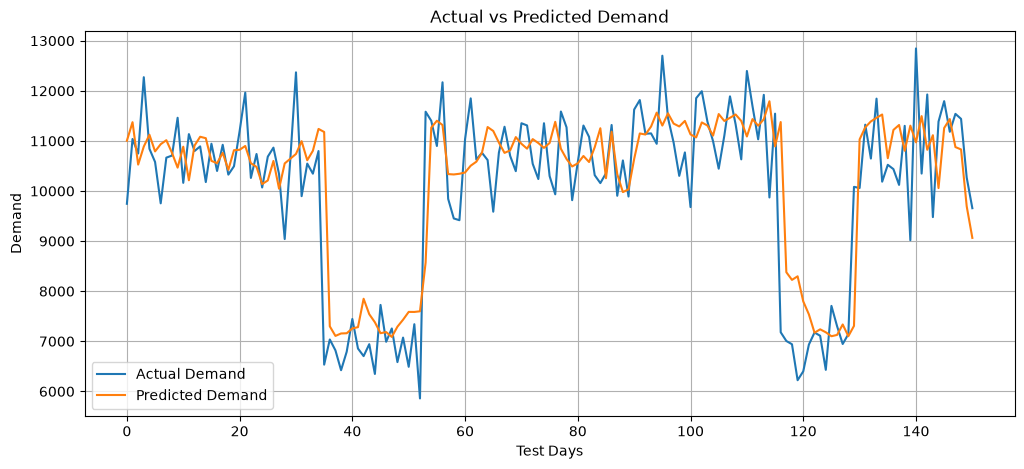

In [41]:
plt.figure(figsize=(12, 5))

plt.plot(y_test.values, label='Actual Demand')
plt.plot(y_pred, label='Predicted Demand')

plt.title('Actual vs Predicted Demand')
plt.xlabel('Test Days')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)

plt.show()

In [42]:
importance = pd.DataFrame({
    'Feature': features,
    'Importance': model.feature_importances_
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance)

     Feature  Importance
4      Lag_1    0.788640
2        Day    0.054693
6  Rolling_7    0.053004
5      Lag_7    0.048370
1      Month    0.033318
3  DayOfWeek    0.017308
0       Year    0.004666


In [43]:
daily_features = df.groupby('Date').agg({
    'Inventory Level': 'mean',
    'Units Sold': 'sum',
    'Units Ordered': 'sum',
    'Price': 'mean',
    'Discount': 'mean',
    'Competitor Pricing': 'mean',
    'Promotion': 'mean',
    'Epidemic': 'mean'
}).reset_index()

daily_features.head()

,Date,Inventory Level,Units Sold,Units Ordered,Price,Discount,Competitor Pricing,Promotion,Epidemic
0,2022-01-01,193.83,8601,20635,68.6690,6.45,70.8500,0.15,0.0
1,2022-01-02,123.85,7684,18801,70.3806,7.35,72.4986,0.20,0.0
2,2022-01-03,103.56,5965,9722,69.7910,9.15,72.1262,0.35,0.0
3,2022-01-04,180.71,7859,9789,69.8443,10.30,72.0545,0.45,0.0
4,2022-01-05,271.52,9621,7392,66.8190,14.35,68.6097,0.70,0.0


In [44]:
daily_data = pd.merge(
    daily_demand,
    daily_features,
    on='Date',
    how='inner'
)

print("Shape:", daily_data.shape)
print("\nColumns:")
print(daily_data.columns.tolist())

daily_data.head()

Shape: (753, 17)

Columns:
['Date', 'Demand', 'Year', 'Month', 'Day', 'DayOfWeek', 'Lag_1', 'Lag_7', 'Rolling_7', 'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount', 'Competitor Pricing', 'Promotion', 'Epidemic']


,Date,Demand,Year,Month,Day,DayOfWeek,Lag_1,Lag_7,Rolling_7,Inventory Level,Units Sold,Units Ordered,Price,Discount,Competitor Pricing,Promotion,Epidemic
0,2022-01-08,12060,2022,1,8,5,11584.0,10060.0,11129.428571,332.95,9980,11944,69.1135,12.55,71.3043,0.60,0.0
1,2022-01-09,11427,2022,1,9,6,12060.0,10814.0,11415.142857,312.53,9661,8547,70.9526,7.75,72.8224,0.15,0.0
2,2022-01-10,11523,2022,1,10,0,11427.0,11317.0,11502.714286,315.28,9928,10209,70.6175,8.85,72.7296,0.30,0.0
3,2022-01-11,12104,2022,1,11,1,11523.0,11469.0,11532.142857,315.11,9957,13993,70.5719,10.00,73.3250,0.40,0.0
4,2022-01-12,11019,2022,1,12,2,12104.0,11724.0,11622.857143,302.13,9279,8996,67.6941,10.30,68.3386,0.40,0.0


In [45]:
features_new = [
    'Year',
    'Month',
    'Day',
    'DayOfWeek',
    'Lag_1',
    'Lag_7',
    'Rolling_7',
    'Inventory Level',
    'Units Ordered',
    'Price',
    'Discount',
    'Competitor Pricing',
    'Promotion',
    'Epidemic'
]

X = daily_data[features_new]
y = daily_data['Demand']

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nFeatures:")
print(features_new)

X shape: (753, 14)
y shape: (753,)

Features:
['Year', 'Month', 'Day', 'DayOfWeek', 'Lag_1', 'Lag_7', 'Rolling_7', 'Inventory Level', 'Units Ordered', 'Price', 'Discount', 'Competitor Pricing', 'Promotion', 'Epidemic']


In [46]:
train_size = int(len(daily_data) * 0.8)

X_train = X.iloc[:train_size]
X_test = X.iloc[train_size:]

y_train = y.iloc[:train_size]
y_test = y.iloc[train_size:]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("Train end:", daily_data['Date'].iloc[train_size - 1])
print("Test start:", daily_data['Date'].iloc[train_size])

X_train: (602, 14)
X_test: (151, 14)
y_train: (602,)
y_test: (151,)
Train end: 2023-09-01 00:00:00
Test start: 2023-09-02 00:00:00


In [47]:
model_new = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=12,
    min_samples_leaf=2
)

model_new.fit(X_train, y_train)

print("Improved model training completed!")

Improved model training completed!


In [48]:
y_pred_new = model_new.predict(X_test)

mae_new = mean_absolute_error(y_test, y_pred_new)
mse_new = mean_squared_error(y_test, y_pred_new)
rmse_new = np.sqrt(mse_new)

print("Improved MAE:", mae_new)
print("Improved MSE:", mse_new)
print("Improved RMSE:", rmse_new)

Improved MAE: 253.10933724675678
Improved MSE: 100552.84965019925
Improved RMSE: 317.1006932351288


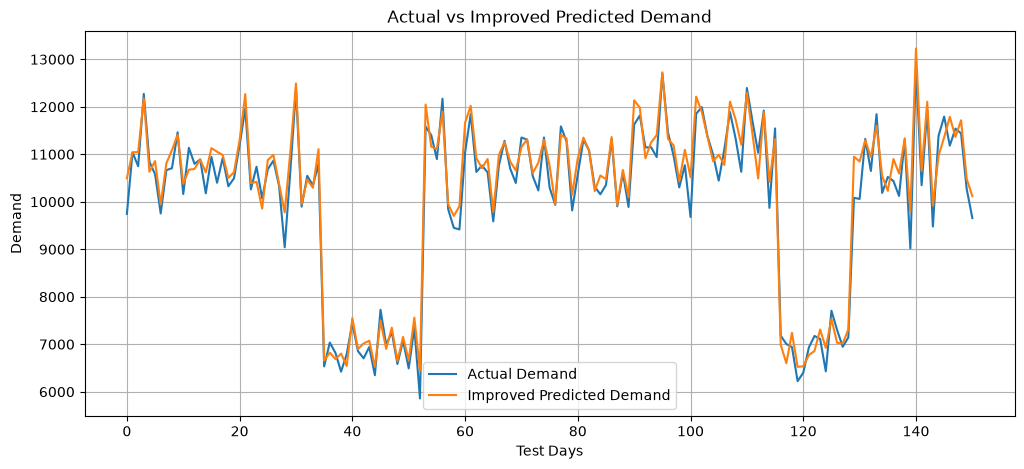

In [49]:
plt.figure(figsize=(12, 5))

plt.plot(y_test.values, label='Actual Demand')
plt.plot(y_pred_new, label='Improved Predicted Demand')

plt.title('Actual vs Improved Predicted Demand')
plt.xlabel('Test Days')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)

plt.show()

In [50]:
importance_new = pd.DataFrame({
    'Feature': features_new,
    'Importance': model_new.feature_importances_
})

importance_new = importance_new.sort_values(
    by='Importance',
    ascending=False
)

print(importance_new)

               Feature  Importance
9                Price    0.354377
11  Competitor Pricing    0.307290
13            Epidemic    0.210596
8        Units Ordered    0.074273
10            Discount    0.025883
6            Rolling_7    0.007537
12           Promotion    0.005907
4                Lag_1    0.004786
2                  Day    0.002889
7      Inventory Level    0.002073
5                Lag_7    0.001661
1                Month    0.001402
3            DayOfWeek    0.000839
0                 Year    0.000486


In [51]:
error = y_test.values - y_pred_new

error_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred_new,
    'Error': error
})

error_df.head(10)

,Actual,Predicted,Error
0,9745,10495.321542,-750.321542
1,11039,11041.815972,-2.815972
2,10748,11047.086269,-299.086269
3,12272,12176.942731,95.057269
4,10843,10632.363702,210.636298
5,10580,10857.072154,-277.072154
6,9754,9942.626075,-188.626075
7,10666,10809.049694,-143.049694
8,10707,11089.244147,-382.244147
9,11462,11410.835185,51.164815


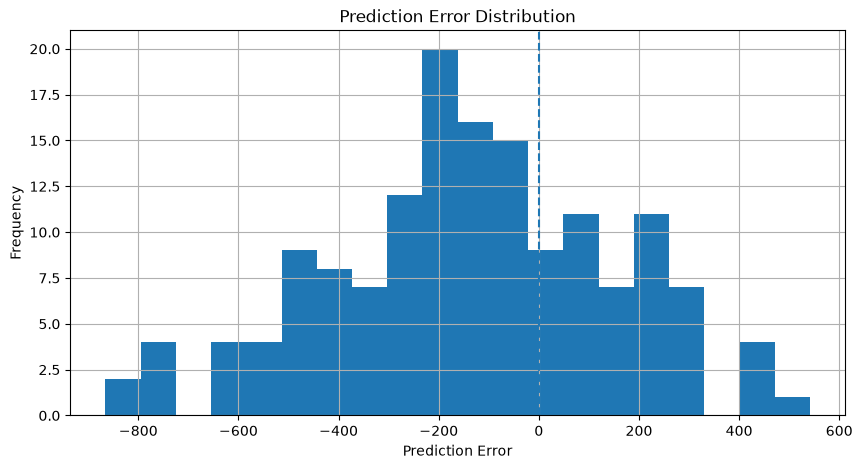

In [52]:
plt.figure(figsize=(10, 5))

plt.hist(error, bins=20)

plt.title('Prediction Error Distribution')
plt.xlabel('Prediction Error')
plt.ylabel('Frequency')

plt.axvline(0, linestyle='--')

plt.grid(True)
plt.show()

In [53]:
from sklearn.metrics import mean_absolute_percentage_error

mape = mean_absolute_percentage_error(y_test, y_pred_new)

print("MAPE:", mape)
print("MAPE (%):", mape * 100)

MAPE: 0.026279090809408153
MAPE (%): 2.627909080940815


In [54]:
print("Features used in model:")
for feature in features_new:
    print("-", feature)

print("\nTarget:")
print("Demand")

print("\nPotential leakage feature:")
print("Units Sold -> NOT USED")

Features used in model:
- Year
- Month
- Day
- DayOfWeek
- Lag_1
- Lag_7
- Rolling_7
- Inventory Level
- Units Ordered
- Price
- Discount
- Competitor Pricing
- Promotion
- Epidemic

Target:
Demand

Potential leakage feature:
Units Sold -> NOT USED


In [55]:
strict_data = daily_data.copy()

future_features = [
    'Inventory Level',
    'Units Ordered',
    'Price',
    'Discount',
    'Competitor Pricing',
    'Promotion',
    'Epidemic'
]

for feature in future_features:
    strict_data[feature] = strict_data[feature].shift(1)

strict_data = strict_data.dropna().reset_index(drop=True)

print("Strict forecasting dataset shape:", strict_data.shape)
print(strict_data.head())

Strict forecasting dataset shape: (752, 17)
        Date  Demand  Year  Month  Day  DayOfWeek    Lag_1    Lag_7  \
0 2022-01-09   11427  2022      1    9          6  12060.0  10814.0   
1 2022-01-10   11523  2022      1   10          0  11427.0  11317.0   
2 2022-01-11   12104  2022      1   11          1  11523.0  11469.0   
3 2022-01-12   11019  2022      1   12          2  12104.0  11724.0   
4 2022-01-13   10990  2022      1   13          3  11019.0  10938.0   

      Rolling_7  Inventory Level  Units Sold  Units Ordered    Price  \
0  11415.142857           332.95        9661        11944.0  69.1135   
1  11502.714286           312.53        9928         8547.0  70.9526   
2  11532.142857           315.28        9957        10209.0  70.6175   
3  11622.857143           315.11        9279        13993.0  70.5719   
4  11522.142857           302.13        9904         8996.0  67.6941   

   Discount  Competitor Pricing  Promotion  Epidemic  
0     12.55             71.3043       0.6

In [56]:
strict_train_size = int(len(strict_data) * 0.8)

strict_train = strict_data.iloc[:strict_train_size]
strict_test = strict_data.iloc[strict_train_size:]

X_strict_train = strict_train[features_new]
y_strict_train = strict_train['Demand']

X_strict_test = strict_test[features_new]
y_strict_test = strict_test['Demand']

print("X_train:", X_strict_train.shape)
print("X_test:", X_strict_test.shape)
print("y_train:", y_strict_train.shape)
print("y_test:", y_strict_test.shape)

print("Train end:", strict_train['Date'].iloc[-1])
print("Test start:", strict_test['Date'].iloc[0])

X_train: (601, 14)
X_test: (151, 14)
y_train: (601,)
y_test: (151,)
Train end: 2023-09-01 00:00:00
Test start: 2023-09-02 00:00:00


In [57]:
strict_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    max_depth=12,
    min_samples_leaf=2
)

strict_model.fit(X_strict_train, y_strict_train)

print("Strict forecasting model training completed!")

Strict forecasting model training completed!


In [58]:
y_strict_pred = strict_model.predict(X_strict_test)

strict_mae = mean_absolute_error(y_strict_test, y_strict_pred)
strict_mse = mean_squared_error(y_strict_test, y_strict_pred)
strict_rmse = np.sqrt(strict_mse)
strict_mape = mean_absolute_percentage_error(y_strict_test, y_strict_pred)

print("Strict MAE:", strict_mae)
print("Strict MSE:", strict_mse)
print("Strict RMSE:", strict_rmse)
print("Strict MAPE:", strict_mape)
print("Strict MAPE (%):", strict_mape * 100)

Strict MAE: 672.9286108040409
Strict MSE: 973801.160428207
Strict RMSE: 986.8136401713381
Strict MAPE: 0.07117551814110863
Strict MAPE (%): 7.117551814110863


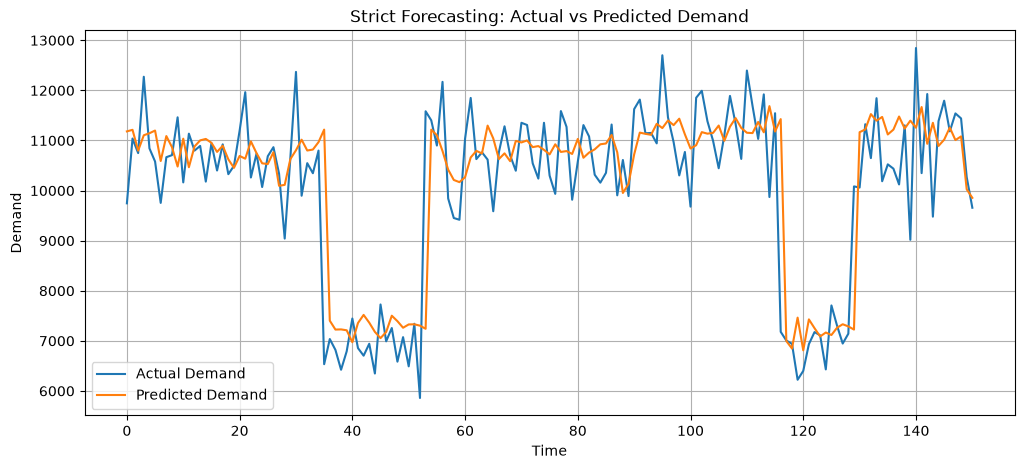

In [59]:
plt.figure(figsize=(12, 5))

plt.plot(y_strict_test.values, label='Actual Demand')
plt.plot(y_strict_pred, label='Predicted Demand')

plt.title('Strict Forecasting: Actual vs Predicted Demand')
plt.xlabel('Time')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)

plt.show()

In [60]:
strict_error = y_strict_test.values - y_strict_pred

strict_error_df = pd.DataFrame({
    'Actual': y_strict_test.values,
    'Predicted': y_strict_pred,
    'Error': strict_error
})

strict_error_df.head(10)


,Actual,Predicted,Error
0,9745,11181.159971,-1436.159971
1,11039,11212.600302,-173.600302
2,10748,10797.267152,-49.267152
3,12272,11104.214717,1167.785283
4,10843,11144.282632,-301.282632
5,10580,11198.035050,-618.035050
6,9754,10589.982158,-835.982158
7,10666,11087.855179,-421.855179
8,10707,10866.672491,-159.672491
9,11462,10479.725783,982.274217


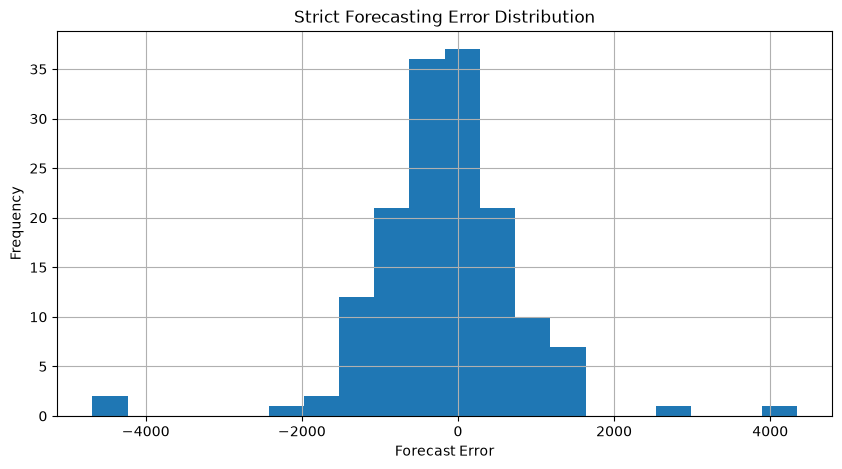

In [61]:
plt.figure(figsize=(10, 5))

plt.hist(strict_error, bins=20)

plt.title('Strict Forecasting Error Distribution')
plt.xlabel('Forecast Error')
plt.ylabel('Frequency')
plt.grid(True)

plt.show()

In [62]:
importance_df = pd.DataFrame({
    'Feature': features_new,
    'Importance': strict_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

importance_df

,Feature,Importance
9,Price,0.250663
11,Competitor Pricing,0.218608
4,Lag_1,0.192191
13,Epidemic,0.163682
2,Day,0.037090
6,Rolling_7,0.034323
1,Month,0.022164
5,Lag_7,0.019942
7,Inventory Level,0.019745
8,Units Ordered,0.015111


In [63]:
importance_df = pd.DataFrame({
    'Feature': features_new,
    'Importance': strict_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df)

               Feature  Importance
9                Price    0.250663
11  Competitor Pricing    0.218608
4                Lag_1    0.192191
13            Epidemic    0.163682
2                  Day    0.037090
6            Rolling_7    0.034323
1                Month    0.022164
5                Lag_7    0.019942
7      Inventory Level    0.019745
8        Units Ordered    0.015111
10            Discount    0.012402
3            DayOfWeek    0.007913
12           Promotion    0.004704
0                 Year    0.001463


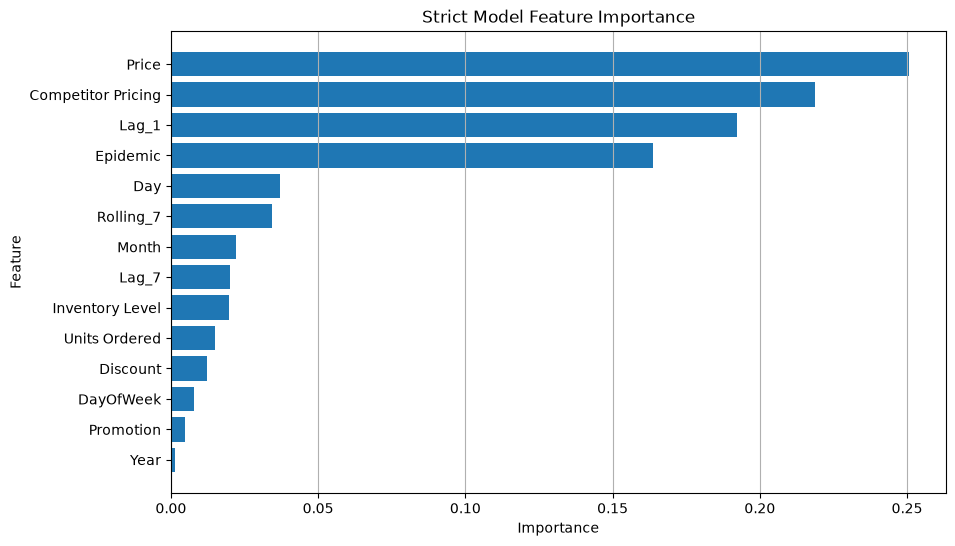

In [64]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df['Feature'],
    importance_df['Importance']
)

plt.xlabel('Importance')
plt.ylabel('Feature')
plt.title('Strict Model Feature Importance')
plt.gca().invert_yaxis()
plt.grid(axis='x')

plt.show()

In [65]:
future_input = X_strict_test.iloc[0:1]

future_prediction = strict_model.predict(future_input)

print("Predicted Future Demand:", future_prediction[0])

Predicted Future Demand: 11181.159971420942


In [66]:
demand_std = y_strict_train.std()

print("Demand Standard Deviation:", demand_std)

Demand Standard Deviation: 1929.6737707871487


In [67]:
z_score = 1.645

safety_stock = z_score * demand_std

print("Safety Stock:", safety_stock)
print("Rounded Safety Stock:", round(safety_stock))

Safety Stock: 3174.3133529448596
Rounded Safety Stock: 3174


In [68]:
average_daily_demand = y_strict_train.mean()

lead_time_days = 3

reorder_point = (
    average_daily_demand * lead_time_days
    + safety_stock
)

print("Average Daily Demand:", average_daily_demand)
print("Lead Time:", lead_time_days, "days")
print("Safety Stock:", round(safety_stock))
print("Reorder Point:", reorder_point)
print("Rounded Reorder Point:", round(reorder_point))

Average Daily Demand: 10523.99833610649
Lead Time: 3 days
Safety Stock: 3174
Reorder Point: 34746.30836126433
Rounded Reorder Point: 34746


In [69]:
current_inventory = strict_data['Inventory Level'].iloc[-1]

if current_inventory <= reorder_point:
    decision = "ORDER NOW"
else:
    decision = "STOCK SUFFICIENT"

print("Current Inventory:", current_inventory)
print("Reorder Point:", round(reorder_point))
print("Decision:", decision)

Current Inventory: 295.78
Reorder Point: 34746
Decision: ORDER NOW


In [70]:
print("Average Inventory Level:",
      strict_data['Inventory Level'].mean())

print("Maximum Inventory Level:",
      strict_data['Inventory Level'].max())

print("Average Daily Demand:",
      y_strict_train.mean())

Average Inventory Level: 301.82484042553193
Maximum Inventory Level: 391.36
Average Daily Demand: 10523.99833610649


In [71]:
inventory_mean = strict_data['Inventory Level'].mean()
inventory_std = strict_data['Inventory Level'].std()

print("Average Inventory:", inventory_mean)
print("Inventory Standard Deviation:", inventory_std)

Average Inventory: 301.82484042553193
Inventory Standard Deviation: 38.817386765306836


In [72]:
inventory_z = 1.645

inventory_threshold = (
    inventory_mean - inventory_z * inventory_std
)

print("Inventory Mean:", inventory_mean)
print("Inventory Std:", inventory_std)
print("Low Inventory Threshold:", inventory_threshold)
print("Rounded Threshold:", round(inventory_threshold))

Inventory Mean: 301.82484042553193
Inventory Std: 38.817386765306836
Low Inventory Threshold: 237.9702391966022
Rounded Threshold: 238


In [73]:
current_inventory = strict_data['Inventory Level'].iloc[-1]

if current_inventory <= 238:
    inventory_status = "ORDER NOW"
else:
    inventory_status = "STOCK SUFFICIENT"

print("Current Inventory:", current_inventory)
print("Low Inventory Threshold:", 238)
print("Inventory Status:", inventory_status)

Current Inventory: 295.78
Low Inventory Threshold: 238
Inventory Status: STOCK SUFFICIENT


In [74]:
forecast_demand = future_prediction[0]
current_inventory = strict_data['Inventory Level'].iloc[-1]
inventory_threshold = 238

if current_inventory <= inventory_threshold:
    decision = "ORDER NOW"
elif forecast_demand > current_inventory:
    decision = "MONITOR / CONSIDER REORDER"
else:
    decision = "STOCK SUFFICIENT"

print("Forecast Demand:", round(forecast_demand, 2))
print("Current Inventory:", round(current_inventory, 2))
print("Inventory Threshold:", inventory_threshold)
print("Final Supply Chain Decision:", decision)

Forecast Demand: 11181.16
Current Inventory: 295.78
Inventory Threshold: 238
Final Supply Chain Decision: MONITOR / CONSIDER REORDER


In [75]:
daily_inventory = df.groupby('Date')['Inventory Level'].sum().reset_index()

print(daily_inventory.head())
print("Average Total Inventory:", daily_inventory['Inventory Level'].mean())
print("Current Total Inventory:", daily_inventory['Inventory Level'].iloc[-1])

        Date  Inventory Level
0 2022-01-01            19383
1 2022-01-02            12385
2 2022-01-03            10356
3 2022-01-04            18071
4 2022-01-05            27152
Average Total Inventory: 30106.284210526315
Current Total Inventory: 29049


In [76]:
# Total inventory statistics
total_inventory_mean = daily_inventory['Inventory Level'].mean()
total_inventory_std = daily_inventory['Inventory Level'].std()

# Demand statistics
demand_mean = y_strict_train.mean()
demand_std = y_strict_train.std()

# Safety stock
z_score = 1.645
safety_stock = z_score * demand_std

# Reorder point
lead_time = 3
reorder_point = (demand_mean * lead_time) + safety_stock

# Current total inventory
current_total_inventory = daily_inventory['Inventory Level'].iloc[-1]

print("Average Daily Demand:", round(demand_mean, 2))
print("Demand Std:", round(demand_std, 2))
print("Safety Stock:", round(safety_stock, 2))
print("Lead Time:", lead_time, "days")
print("Reorder Point:", round(reorder_point, 2))
print("Current Total Inventory:", current_total_inventory)

Average Daily Demand: 10524.0
Demand Std: 1929.67
Safety Stock: 3174.31
Lead Time: 3 days
Reorder Point: 34746.31
Current Total Inventory: 29049


In [77]:
current_inventory = current_total_inventory
reorder_point = reorder_point

if current_inventory <= reorder_point:
    final_decision = "ORDER NOW"
else:
    final_decision = "STOCK SUFFICIENT"

print("Current Inventory:", round(current_inventory, 2))
print("Reorder Point:", round(reorder_point, 2))
print("Final Supply Chain Decision:", final_decision)

Current Inventory: 29049
Reorder Point: 34746.31
Final Supply Chain Decision: ORDER NOW


In [78]:
print("=" * 50)
print("   DYNAMIC SUPPLY CHAIN PREDICTOR")
print("=" * 50)

print(f"Forecast Demand        : {future_prediction[0]:.2f}")
print(f"Current Total Inventory: {current_total_inventory:.2f}")
print(f"Safety Stock           : {safety_stock:.2f}")
print(f"Reorder Point          : {reorder_point:.2f}")
print(f"Lead Time              : {lead_time} days")
print(f"Final Decision         : {final_decision}")

print("=" * 50)


   DYNAMIC SUPPLY CHAIN PREDICTOR
Forecast Demand        : 11181.16
Current Total Inventory: 29049.00
Safety Stock           : 3174.31
Reorder Point          : 34746.31
Lead Time              : 3 days
Final Decision         : ORDER NOW


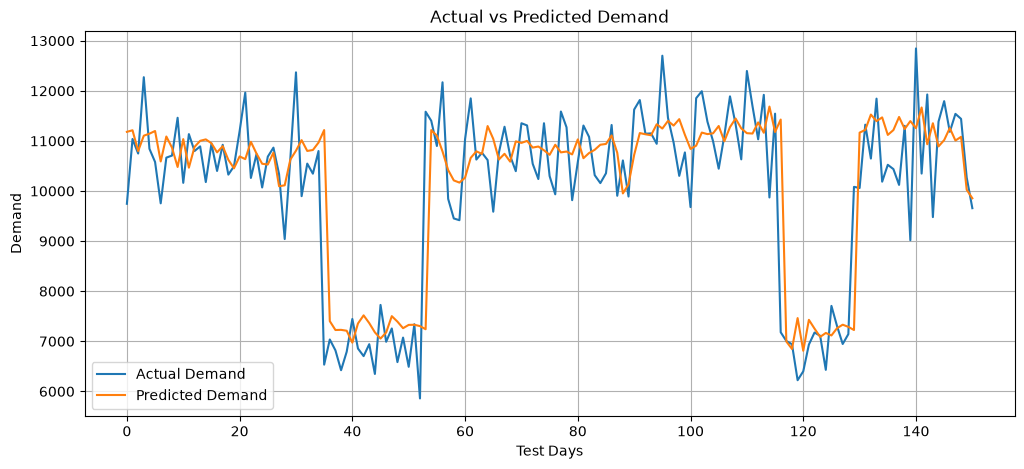

In [79]:


plt.figure(figsize=(12, 5))

plt.plot(
    y_strict_test.values,
    label='Actual Demand'
)

plt.plot(
    y_strict_pred,
    label='Predicted Demand'
)

plt.title('Actual vs Predicted Demand')
plt.xlabel('Test Days')
plt.ylabel('Demand')
plt.legend()
plt.grid(True)

plt.show()

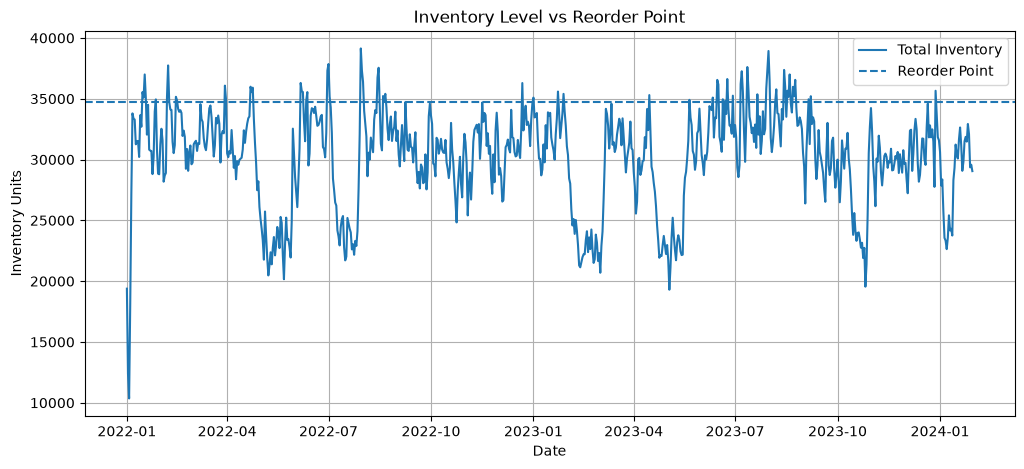

In [80]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_inventory['Date'],
    daily_inventory['Inventory Level'],
    label='Total Inventory'
)

plt.axhline(
    y=reorder_point,
    linestyle='--',
    label='Reorder Point'
)

plt.title('Inventory Level vs Reorder Point')
plt.xlabel('Date')
plt.ylabel('Inventory Units')
plt.legend()
plt.grid(True)

plt.show()

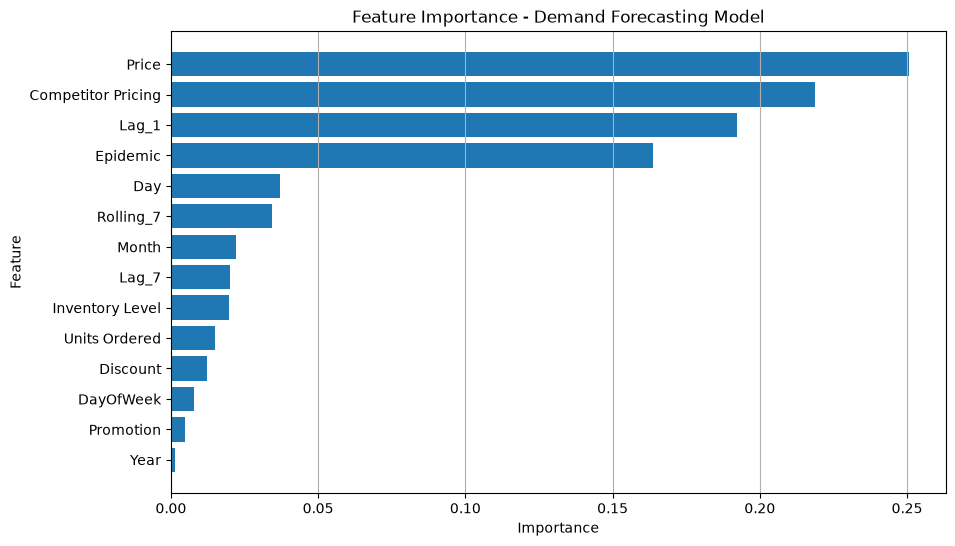

In [81]:
importance_df = pd.DataFrame({
    'Feature': features_new,
    'Importance': strict_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df['Feature'],
    importance_df['Importance']
)

plt.title('Feature Importance - Demand Forecasting Model')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.gca().invert_yaxis()
plt.grid(axis='x')

plt.show()

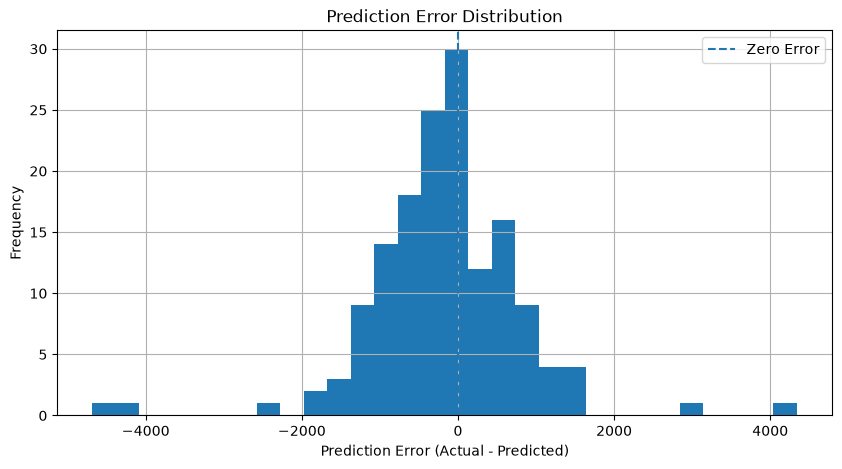

In [82]:
plt.figure(figsize=(10, 5))

plt.hist(
    strict_error,
    bins=30
)

plt.axvline(
    x=0,
    linestyle='--',
    label='Zero Error'
)

plt.title('Prediction Error Distribution')
plt.xlabel('Prediction Error (Actual - Predicted)')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)

plt.show()

In [83]:
print("=" * 60)
print("             FINAL MODEL RESULTS")
print("=" * 60)

print("\nBASELINE MODEL")
print("MAE  :", round(714.92, 2))
print("RMSE :", round(998.30, 2))

print("\nIMPROVED MODEL")
print("MAE  :", round(253.11, 2))
print("RMSE :", round(317.10, 2))
print("MAPE :", "2.63%")

print("\nSTRICT FUTURE FORECASTING")
print("MAE  :", round(strict_mae, 2))
print("RMSE :", round(strict_rmse, 2))
print("MAPE :", f"{strict_mape * 100:.2f}%")

print("\nSUPPLY CHAIN DECISION")
print("Forecast Demand :", round(future_prediction[0], 2))
print("Current Inventory :", round(current_total_inventory, 2))
print("Safety Stock :", round(safety_stock, 2))
print("Reorder Point :", round(reorder_point, 2))
print("Lead Time :", lead_time, "days")
print("Decision :", final_decision)

print("=" * 60)

             FINAL MODEL RESULTS

BASELINE MODEL
MAE  : 714.92
RMSE : 998.3

IMPROVED MODEL
MAE  : 253.11
RMSE : 317.1
MAPE : 2.63%

STRICT FUTURE FORECASTING
MAE  : 672.93
RMSE : 986.81
MAPE : 7.12%

SUPPLY CHAIN DECISION
Forecast Demand : 11181.16
Current Inventory : 29049
Safety Stock : 3174.31
Reorder Point : 34746.31
Lead Time : 3 days
Decision : ORDER NOW


In [84]:
print("=" * 60)
print("                    CONCLUSION")
print("=" * 60)

print("""
The Dynamic Supply Chain Predictor uses machine learning
to forecast daily demand and support inventory decisions.

A Random Forest model was trained using historical demand,
lag features, rolling demand, pricing, competitor pricing,
inventory, promotion, and epidemic-related information.

The strict forecasting model achieved a MAPE of approximately
7.12%, showing reasonable demand forecasting performance.

The system also calculates safety stock and reorder point
to identify potential inventory shortages.

For the current data:
- Forecast Demand = 11,181.16 units/day
- Current Inventory = 29,049 units
- Reorder Point = 34,746.31 units
- Final Decision = ORDER NOW

Therefore, the system can help supply-chain managers make
data-driven demand forecasting and replenishment decisions.
""")

print("=" * 60)

                    CONCLUSION

The Dynamic Supply Chain Predictor uses machine learning
to forecast daily demand and support inventory decisions.

A Random Forest model was trained using historical demand,
lag features, rolling demand, pricing, competitor pricing,
inventory, promotion, and epidemic-related information.

The strict forecasting model achieved a MAPE of approximately
7.12%, showing reasonable demand forecasting performance.

The system also calculates safety stock and reorder point
to identify potential inventory shortages.

For the current data:
- Forecast Demand = 11,181.16 units/day
- Current Inventory = 29,049 units
- Reorder Point = 34,746.31 units
- Final Decision = ORDER NOW

Therefore, the system can help supply-chain managers make
data-driven demand forecasting and replenishment decisions.



In [85]:
print("=" * 60)
print("                   FUTURE SCOPE")
print("=" * 60)

print("""
1. Real-time inventory monitoring can be integrated.
2. LSTM, GRU, or advanced time-series models can be used
   for improved demand forecasting.
3. Demand forecasting can be performed separately for each
   store and product.
4. Real-time weather and market data can be integrated.
5. Supplier lead time can be estimated dynamically.
6. Automated purchase-order generation can be added.
7. A Streamlit or Flask dashboard can be developed for
   real-time visualization and decision making.
8. The system can be deployed on cloud infrastructure
   for continuous supply-chain monitoring.
""")

print("=" * 60)

                   FUTURE SCOPE

1. Real-time inventory monitoring can be integrated.
2. LSTM, GRU, or advanced time-series models can be used
   for improved demand forecasting.
3. Demand forecasting can be performed separately for each
   store and product.
4. Real-time weather and market data can be integrated.
5. Supplier lead time can be estimated dynamically.
6. Automated purchase-order generation can be added.
7. A Streamlit or Flask dashboard can be developed for
   real-time visualization and decision making.
8. The system can be deployed on cloud infrastructure
   for continuous supply-chain monitoring.

